# Classification with a single-layer perceptron

In [1]:
import numpy as np
import matplotlib.pyplot as plt

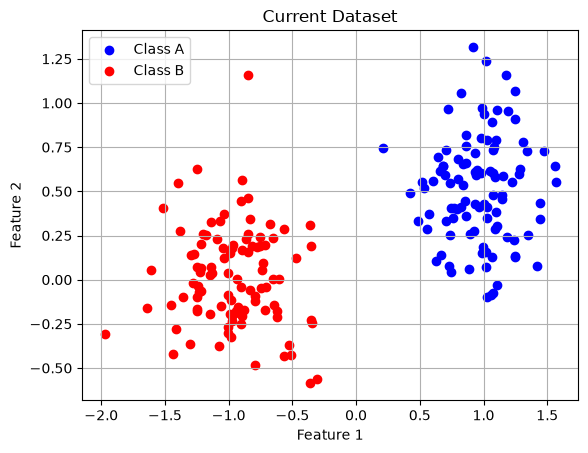

In [2]:
from data_generation import generate_linearly_separable_data, plot_data, generate_non_linearly_separable_data

X, T = generate_linearly_separable_data()
plot_data(X, T)


### 1st algorithm: perceptron learning rule, sequential (online) mode 

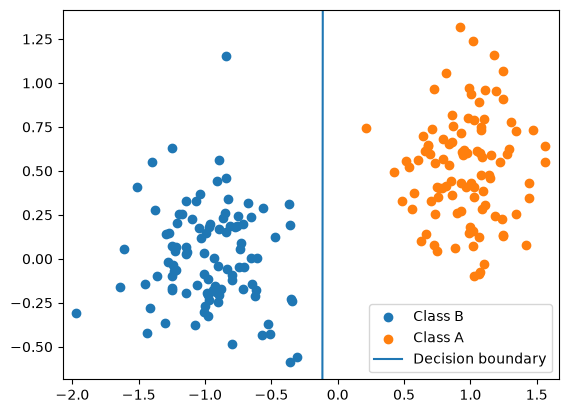

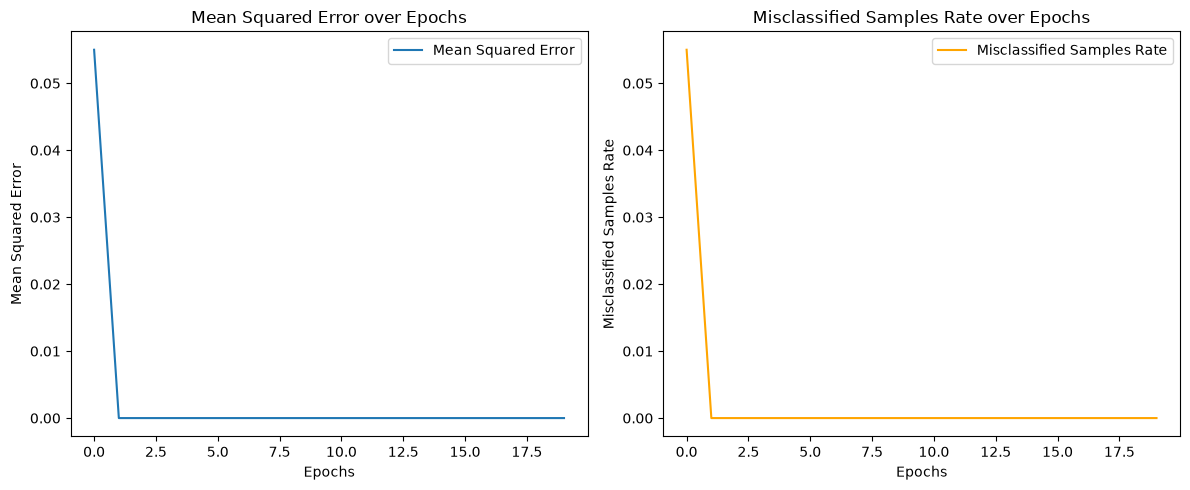

In [3]:
from algorithms import PerceptronRulePerceptron

def step_function(x):
    return np.where(x >= 0, 1, 0)

perceptron = PerceptronRulePerceptron(
                        input_size=2, 
                        output_size=1, 
                        learning_rate=0.09,
                        activation_function=step_function)

perceptron.train(X, T, epochs=20)

perceptron.plot_metrics()



### 2nd algorithm: delta (Widrow-Hoff) rule, sequential (online) mode 

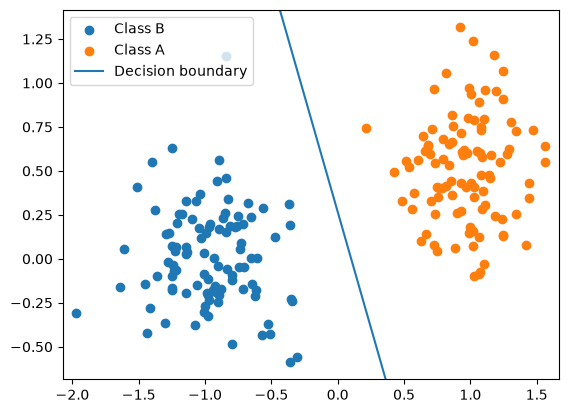

Final weights: [[ 0.87510791  0.33216848 -0.08884849]]


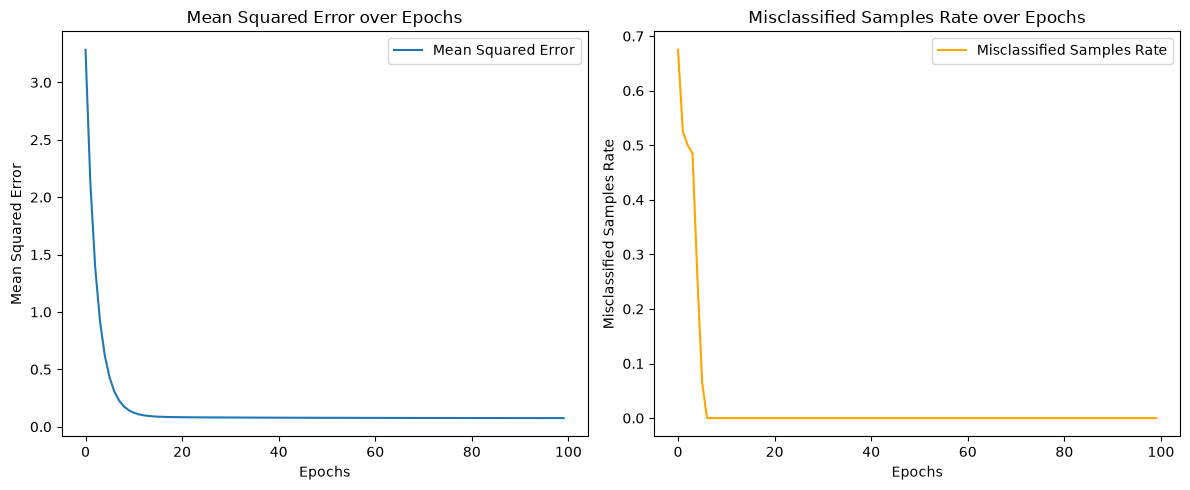

In [4]:
from algorithms import DeltaRulePerceptron

def delta_rule_activation_function(x):
    return np.where(x >= 0, 1, -1)

T_delta = np.where(T == 0, -1, T)

perceptron = DeltaRulePerceptron(
                        input_size=2, 
                        output_size=1, 
                        learning_rate=0.001,
                        activation_function=delta_rule_activation_function)

perceptron.train(X, T_delta, epochs=100)
print("Final weights:", perceptron.weights)
perceptron.plot_metrics()



### 3rd algorithm: delta (Widrow-Hoff) rule, batch mode, using the matrix formulation

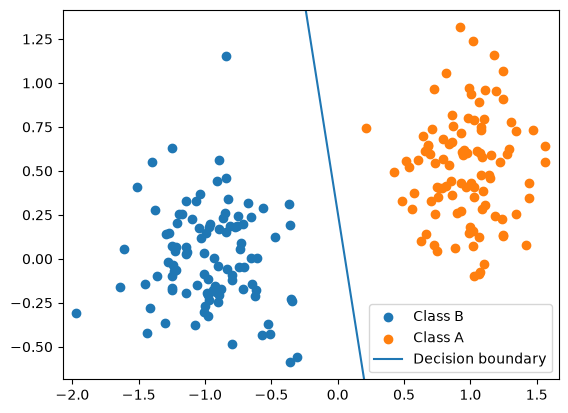

Final weights: [[ 0.90609672  0.18975599 -0.05021227]]


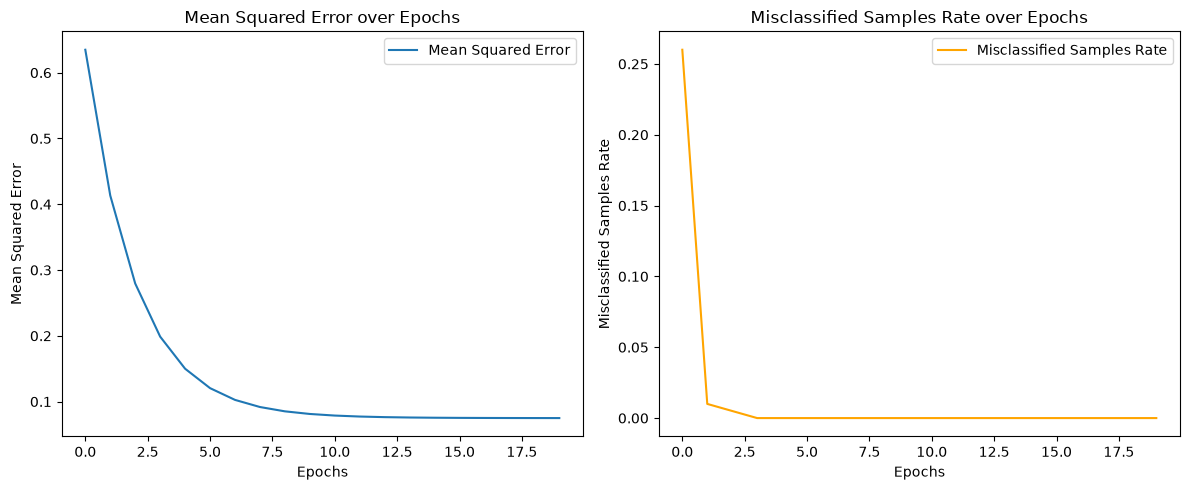

In [5]:
from algorithms import DeltaRuleBatchPerceptron

perceptron = DeltaRuleBatchPerceptron(
                        input_size=2,
                        output_size=1,
                        learning_rate=0.001, 
                        activation_function=delta_rule_activation_function)

perceptron.train(X, T_delta, epochs=20)
print("Final weights:", perceptron.weights)
perceptron.plot_metrics()

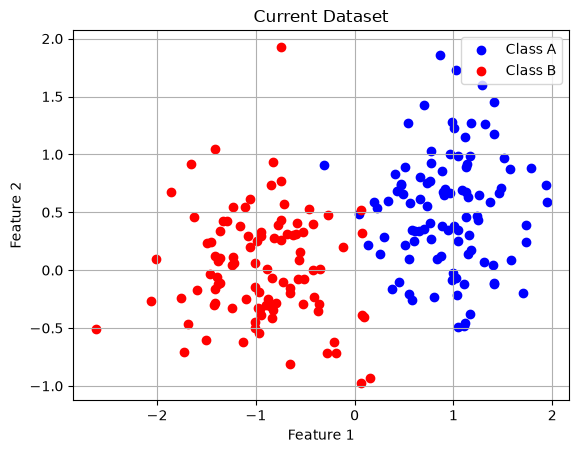

In [6]:
from data_generation import generate_non_linearly_separable_data
plot_data(*generate_non_linearly_separable_data())

In [7]:
# test plotting function

def plot_metrics_comparison(perceptron_rule = None, delta_rule = None, delta_rule_batch = None, saved_fig_name = None):

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    if perceptron_rule is not None:
        plt.plot(perceptron_rule.mean_squared_error, label="Perceptron Rule")
    if delta_rule is not None:
        plt.plot(delta_rule.mean_squared_error, label="Delta Rule")
    if delta_rule_batch is not None:
        plt.plot(delta_rule_batch.mean_squared_error, label="Delta Rule Batch")
    plt.title("Mean Squared Error Comparison")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    
    plt.subplot(1, 2, 2)
    if perceptron_rule is not None:
        plt.plot(perceptron_rule.misclassified_samples_rate, label="Perceptron Rule")
    if delta_rule is not None:
        plt.plot(delta_rule.misclassified_samples_rate, label="Delta Rule")
    if delta_rule_batch is not None:
        plt.plot(delta_rule_batch.misclassified_samples_rate, label="Delta Rule Batch")
    plt.title("Misclassified Samples Rate Comparison")
    plt.xlabel("Epochs")
    plt.ylabel("Misclassified Samples Rate")
    plt.legend()

    if saved_fig_name is not None:
        plt.savefig(saved_fig_name)

    plt.show()

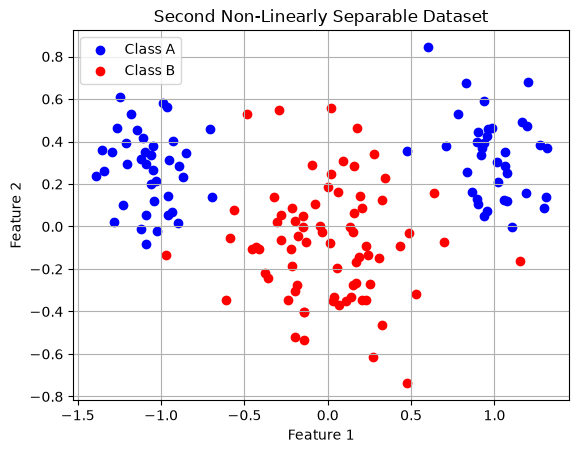

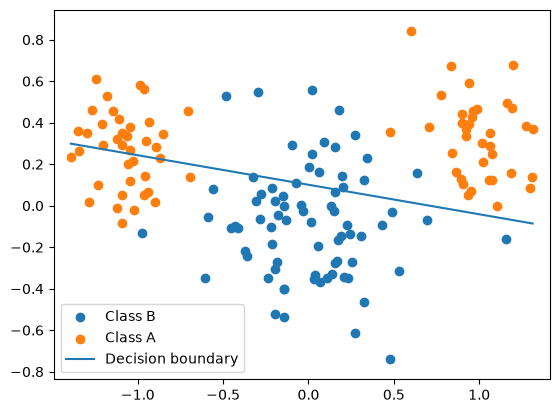

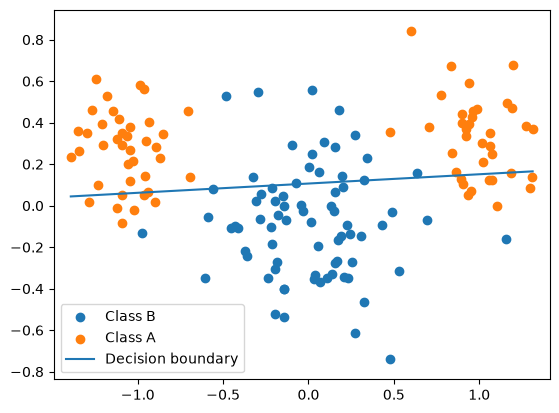

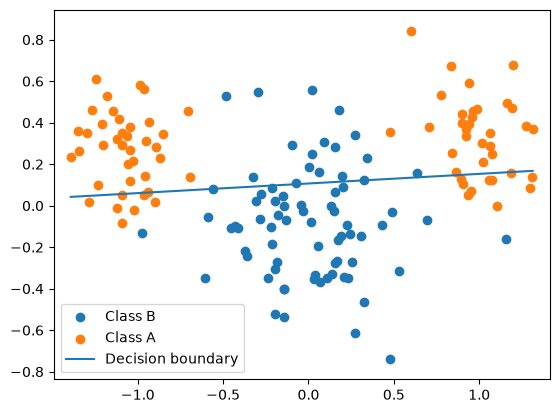

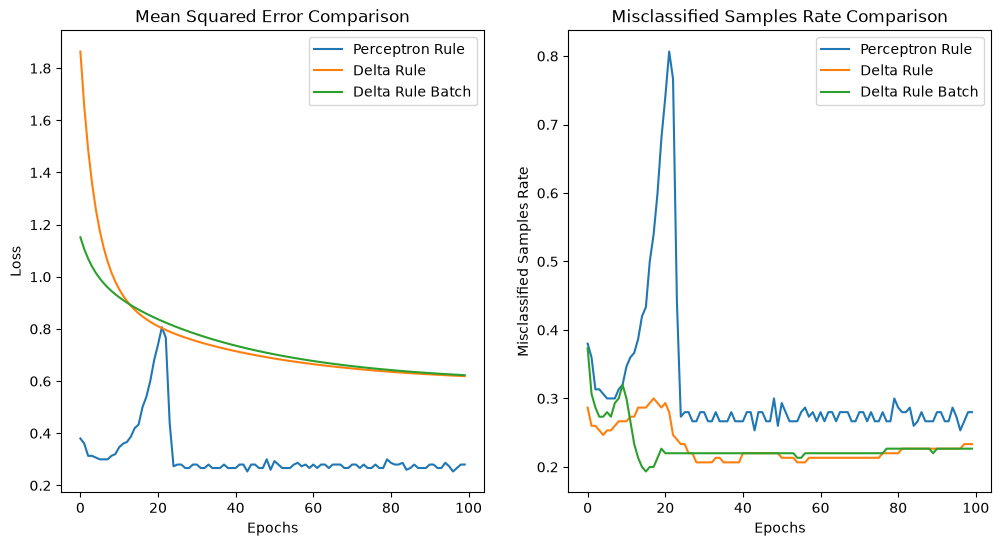

In [8]:
# Test on second non-linearly separable dataset

from data_generation import generate_non_linearly_separable_data_second_version, plot_data
from algorithms import PerceptronRulePerceptron, DeltaRulePerceptron, DeltaRuleBatchPerceptron


perceptron_rule = PerceptronRulePerceptron(
                        input_size=2,
                        output_size=1,
                        learning_rate=0.001,
                        activation_function=step_function)

delta_rule = DeltaRulePerceptron(
                        input_size=2,
                        output_size=1,
                        learning_rate=0.001,
                        activation_function=delta_rule_activation_function)

delta_rule_batch = DeltaRuleBatchPerceptron(
                        input_size=2,
                        output_size=1,
                        learning_rate=0.001,
                        activation_function=delta_rule_activation_function)

X_og, T_og = generate_non_linearly_separable_data_second_version()


# test 1: remove 25% of the data points from each class

class_A_indices = np.where(T_og == 1)[0]
class_B_indices = np.where(T_og == 0)[0]

n_A = int(0.25 * len(class_A_indices))
n_B = int(0.25 * len(class_B_indices))

remove_A_indices = np.random.choice(class_A_indices, size=n_A, replace=False)
remove_B_indices = np.random.choice(class_B_indices, size=n_B, replace=False)

all_remove_indices = np.concatenate((remove_A_indices, remove_B_indices))

X = np.delete(X_og, all_remove_indices, axis=1)
T = np.delete(T_og, all_remove_indices)

T_delta = np.where(T == 0, -1, T)

plot_data(X, T, title="Second Non-Linearly Separable Dataset")

perceptron_rule.train(X, T, epochs=100)
delta_rule.train(X, T_delta, epochs=100)
delta_rule_batch.train(X, T_delta, epochs=100)

# plot metrics for all three algorithms on the same plot

plot_metrics_comparison(perceptron_rule, delta_rule, delta_rule_batch, saved_fig_name="removed_25_A_25_B.png")

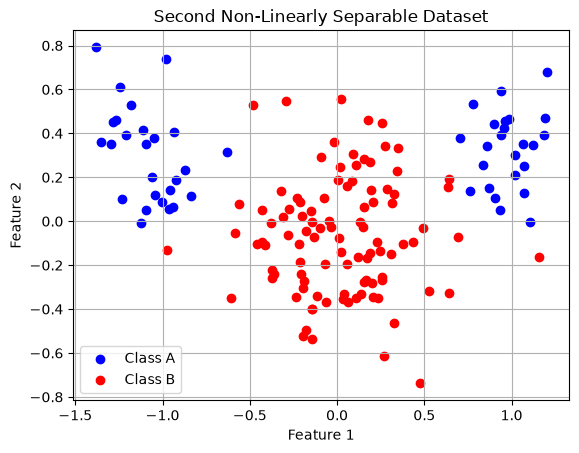

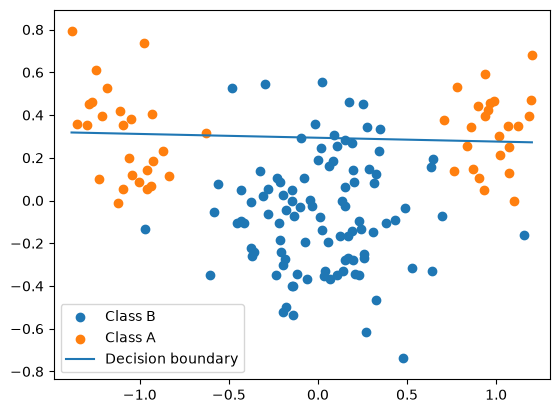

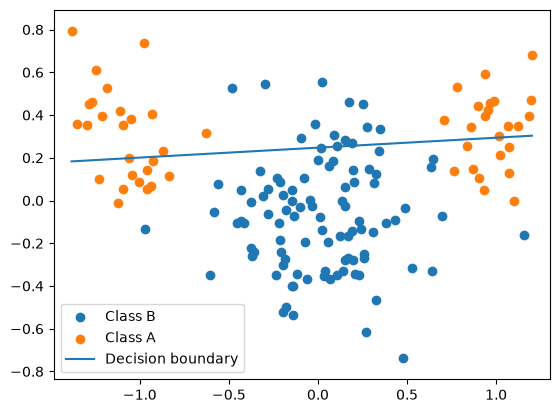

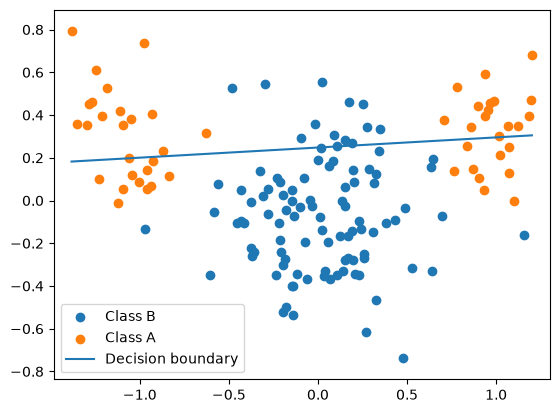

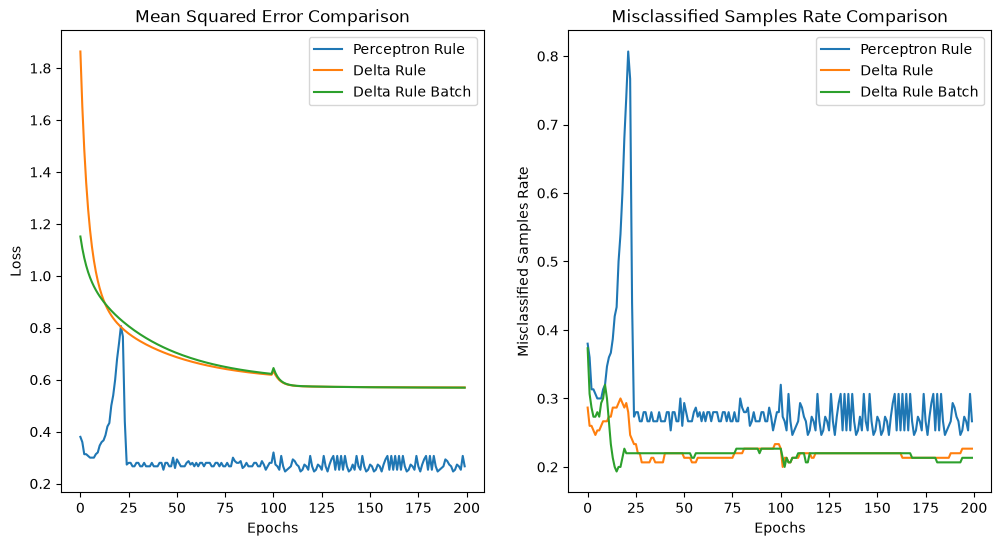

In [9]:
# remove 50% of the data points from class A

class_A_indices = np.where(T_og == 1)[0]

n_A = int(0.5 * len(class_A_indices))

remove_A_indices = np.random.choice(class_A_indices, size=n_A, replace=False)

X = np.delete(X_og, remove_A_indices, axis=1)
T = np.delete(T_og, remove_A_indices)

T_delta = np.where(T == 0, -1, T)

plot_data(X, T, title="Second Non-Linearly Separable Dataset")

perceptron_rule.train(X, T, epochs=100)
delta_rule.train(X, T_delta, epochs=100)
delta_rule_batch.train(X, T_delta, epochs=100)

# plot metrics for all three algorithms on the same plot

plot_metrics_comparison(perceptron_rule, delta_rule, delta_rule_batch, saved_fig_name="removed_50_A.png")

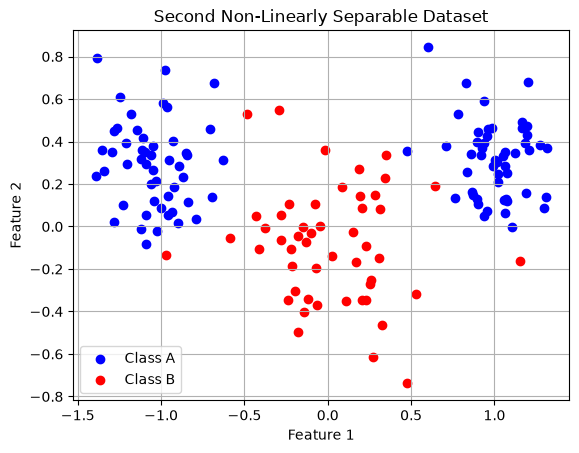

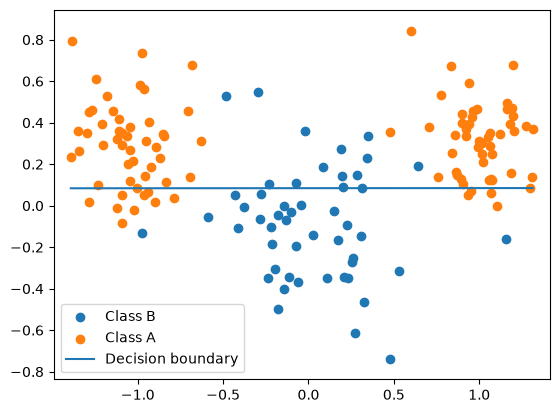

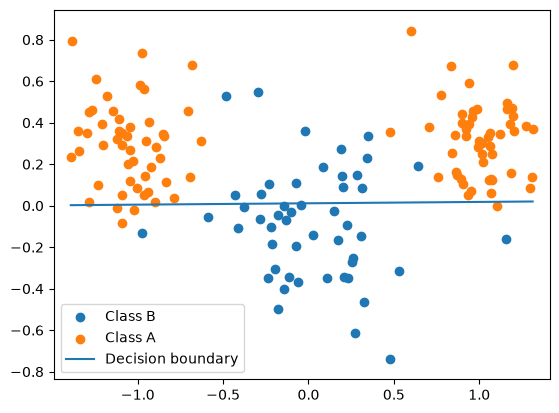

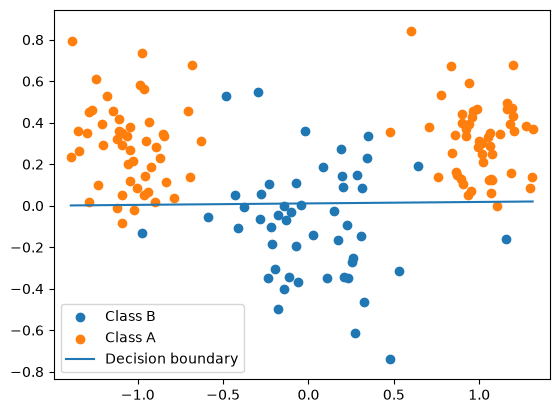

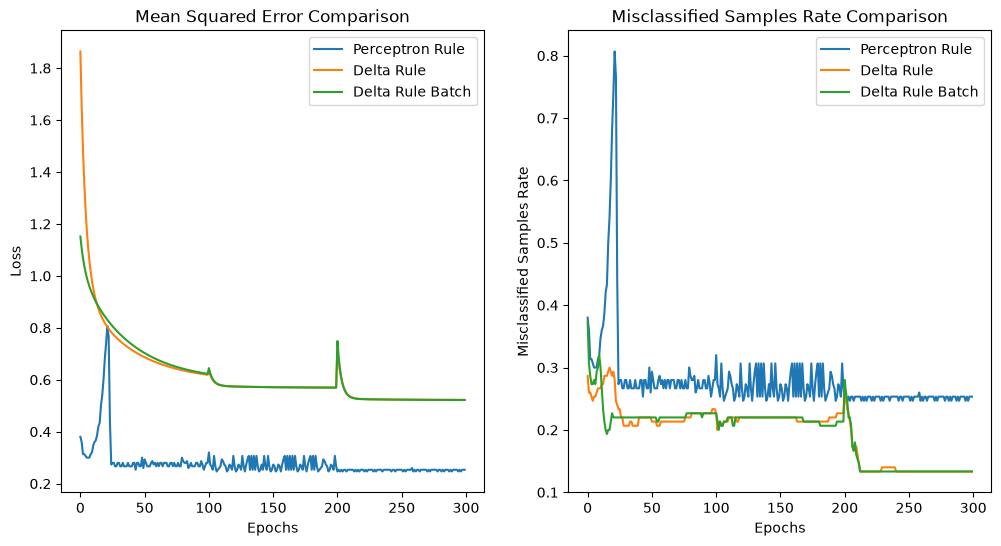

In [10]:
# remove 50% of the data points from class B

class_B_indices = np.where(T_og == 0)[0]

n_B = int(0.5 * len(class_B_indices))

remove_B_indices = np.random.choice(class_B_indices, size=n_B, replace=False)

X = np.delete(X_og, remove_B_indices, axis=1)
T = np.delete(T_og, remove_B_indices)

T_delta = np.where(T == 0, -1, T)

plot_data(X, T, title="Second Non-Linearly Separable Dataset")

perceptron_rule.train(X, T, epochs=100)
delta_rule.train(X, T_delta, epochs=100)
delta_rule_batch.train(X, T_delta, epochs=100)

# plot metrics for all three algorithms on the same plot

plot_metrics_comparison(perceptron_rule, delta_rule, delta_rule_batch, saved_fig_name="removed_50_B.png")

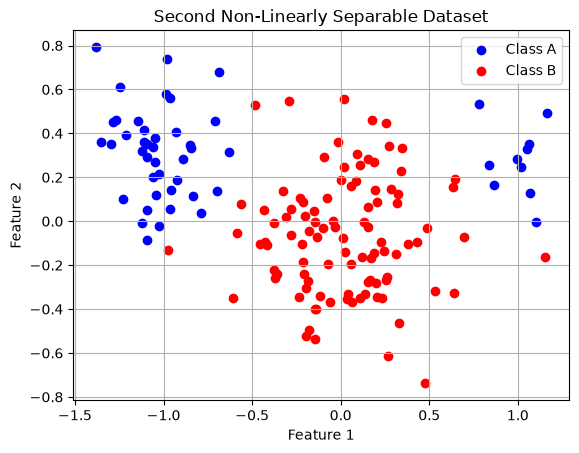

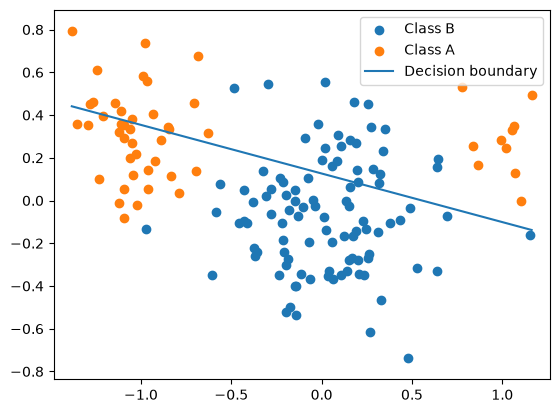

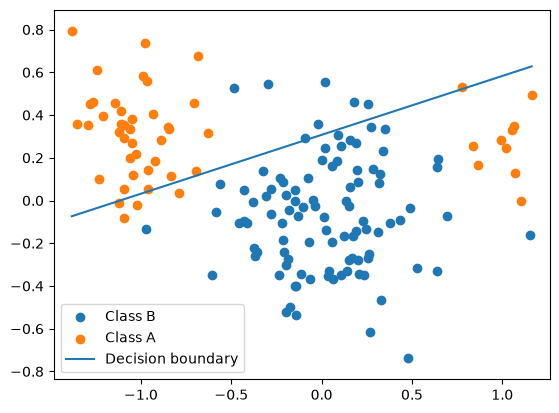

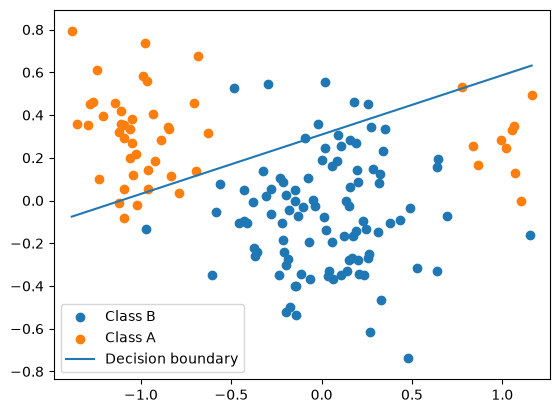

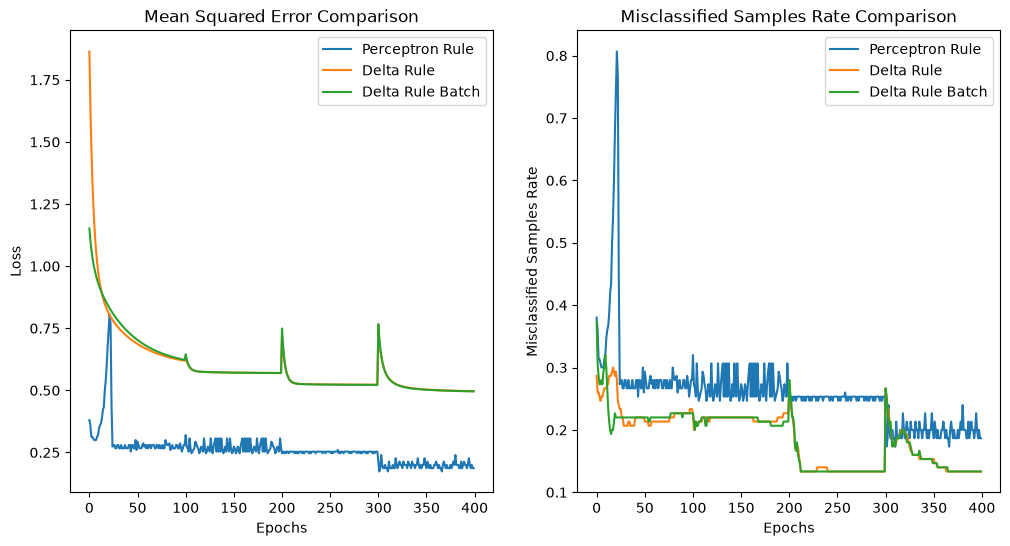

In [11]:
# remove 20% of the data points from class A where A(0, :) < 0 and 80% of the data points from class A where A(0, :) > 0

class_A_indices_neg = np.where((T_og == 1) & (X_og[0, :] < 0))[0]
class_A_indices_pos = np.where((T_og == 1) & (X_og[0, :] > 0))[0]

n_A_neg = int(0.2 * len(class_A_indices_neg))
n_A_pos = int(0.8 * len(class_A_indices_pos))

remove_A_indices_neg = np.random.choice(class_A_indices_neg, size=n_A_neg, replace=False)
remove_A_indices_pos = np.random.choice(class_A_indices_pos, size=n_A_pos, replace=False)

remove_A_indices = np.concatenate([remove_A_indices_neg, remove_A_indices_pos])

X = np.delete(X_og, remove_A_indices, axis=1)
T = np.delete(T_og, remove_A_indices)

T_delta = np.where(T == 0, -1, T)

plot_data(X, T, title="Second Non-Linearly Separable Dataset")

perceptron_rule.train(X, T, epochs=100)
delta_rule.train(X, T_delta, epochs=100)
delta_rule_batch.train(X, T_delta, epochs=100)

# plot metrics for all three algorithms on the same plot

plot_metrics_comparison(perceptron_rule, delta_rule, delta_rule_batch, saved_fig_name="removed_20_A_neg_80_A_pos.png")